# 05.3 – Affordability matrix (SQ4), ANOVA and correlations

**Owner:** Luca · **Extra points:** ANOVA and correlation analysis, each with a p-value

This notebook uses the SQLite database `db/sci_alpi.db` (built by `05_sqlite_database.ipynb`) and answers three questions with the data that is already reliable. The `resorts` table has **293 ski areas, one row each** (repaired in notebook `02.4`). Every result is also recomputed for the **Alpine analysis set only** (269 areas: the 275 candidates of the snow roster without six areas that are outside the Alps by geography; the 18 areas that the roster already excludes are out as well) to show that the scope decision does not change the conclusions.

1. **SQ4 – affordability:** how many hours of net work does a day pass cost, for a skier from each country in each destination country (a 4 × 4 matrix)?
2. **ANOVA:** do day-pass prices differ between Switzerland, Austria, Italy and France?
3. **Correlation:** which resort features go together with the day-pass price?

**Not in this notebook:** the chi-squared test of closed facilities against snow-risk classes (SQ5, see notebook `08_closures_chi_squared.ipynb`) and the models for SQ3 (notebook `07_clustering_and_regression.ipynb`). The ANOVA of snow loss by country and elevation needs a validated snow table for all resorts, which does not exist yet (see `docs/snow_expansion_status.md`).

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
DB_PATH = ROOT / "db" / "sci_alpi.db"
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
assert DB_PATH.exists(), "Run notebook 05_sqlite_database.ipynb first (it creates db/sci_alpi.db)."

con = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)    # read-only: this notebook only reads
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

def sql(query, params=()):
    return pd.read_sql_query(query, con, params=params)

# Chart style: one blue for the data, grey text, no frame
BLUE_LIGHT, BLUE_MID, BLUE_DARK = "#cde2fb", "#3987e5", "#0d366b"
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e3e2de"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT,
                     "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Database:", DB_PATH.relative_to(ROOT))

Database: db/sci_alpi.db


## 1. SQ4 – hours of net work for one day pass

For a skier from country *A* who skis in country *B*: `average day-pass price in B (EUR) / net hourly earnings in A (EUR)`. The price in the destination country is already in euros. The earnings come from the view `v_latest_earnings` (latest year with data: 2023 for CH, 2025 for AT, FR and IT). `CROSS JOIN` pairs every origin with every destination, which gives the 16 cells of the matrix.

The diagonal (origin = destination) is the result of notebook 05: a person who skis in their own country.

In [2]:
q_matrix = sql('''
    WITH dest AS (
        SELECT country AS destination,
               COUNT(*)           AS n_resorts,
               AVG(price_day_eur) AS avg_price_eur
        FROM resorts
        WHERE price_day_eur IS NOT NULL
        GROUP BY country
    )
    SELECT o.country                                   AS origin,
           d.destination,
           o.year                                      AS earnings_year,
           ROUND(o.net_earnings_hour_eur, 2)           AS net_hourly_eur,
           d.n_resorts,
           ROUND(d.avg_price_eur, 2)                   AS avg_price_eur,
           d.avg_price_eur / o.net_earnings_hour_eur   AS work_hours
    FROM v_latest_earnings o
    CROSS JOIN dest d
    ORDER BY o.country, d.destination
''')
matrix = q_matrix.pivot(index="origin", columns="destination", values="work_hours")
order = ["CH", "AT", "FR", "IT"]
matrix = matrix.loc[order, order]
matrix.round(2)

destination,CH,AT,FR,IT
origin,,,,
CH,1.56,1.55,1.06,1.31
AT,3.02,3.01,2.05,2.53
FR,3.96,3.94,2.68,3.32
IT,4.61,4.58,3.12,3.86


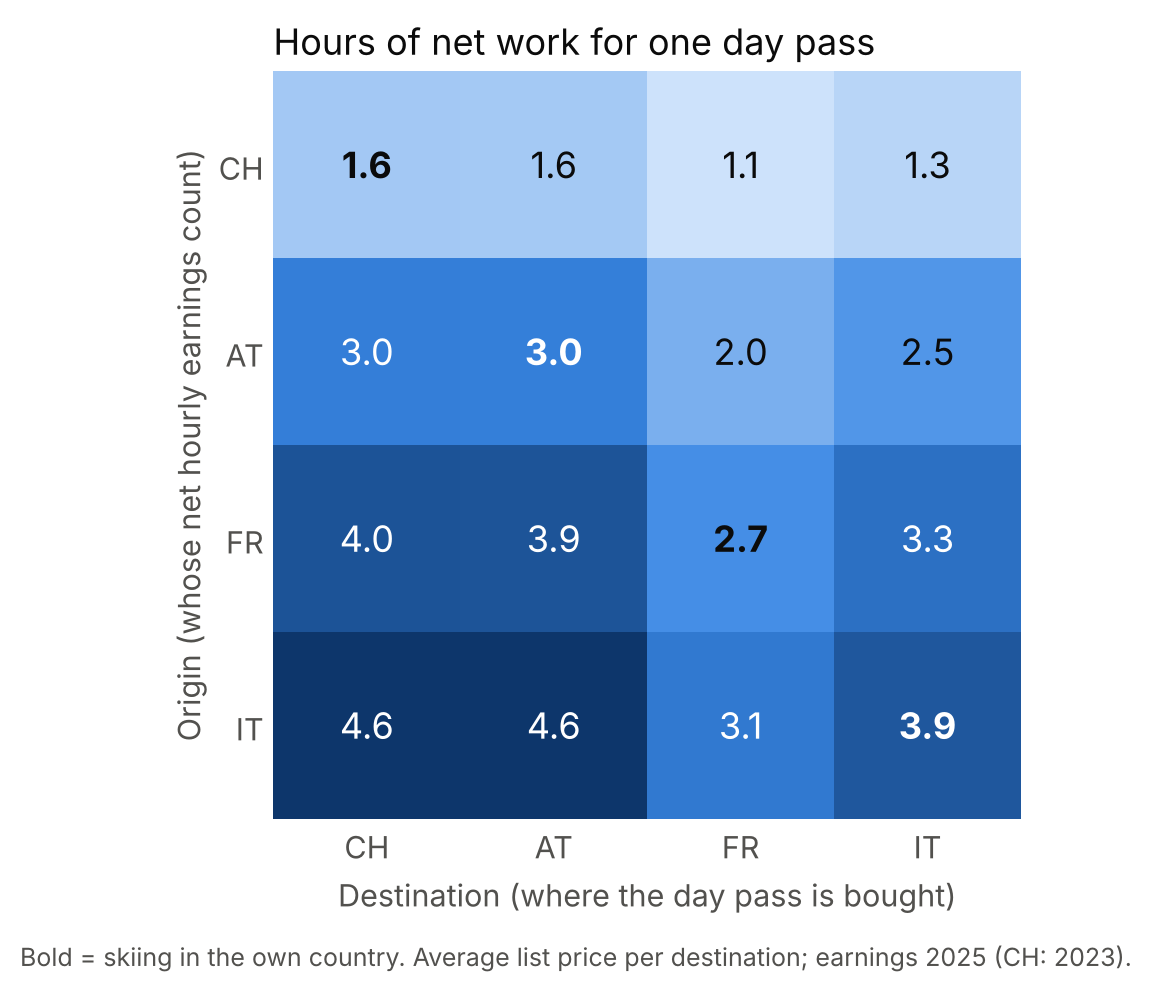

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
im = ax.imshow(matrix.values, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("blue", [BLUE_LIGHT, BLUE_MID, BLUE_DARK]))
ax.set_xticks(range(4), labels=order)
ax.set_yticks(range(4), labels=order)
ax.set_xlabel("Destination (where the day pass is bought)")
ax.set_ylabel("Origin (whose net hourly earnings count)")
for i in range(4):
    for j in range(4):
        v = matrix.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=13,
                color="white" if v > matrix.values.mean() else INK, fontweight="bold" if i == j else "normal")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
ax.set_title("Hours of net work for one day pass", loc="left", fontsize=13, color=INK)
fig.text(0.01, -0.02, "Bold = skiing in the own country. Average list price per destination; earnings 2025 (CH: 2023).",
         fontsize=9, color=INK_SOFT)
fig.tight_layout()
fig.savefig(FIG_DIR / "sq4_work_hours_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the matrix.** A skier from Italy needs about 4.6 hours of net work for a day pass in Switzerland or Austria, 3.9 hours in Italy and 3.1 hours in France. A Swiss skier needs between 1.1 and 1.6 hours in every country. An Italian skiing in Switzerland therefore works about 0.75 hours (19 %) longer than at home. In every row France is the cheapest destination. The origin matters more than the destination: net hourly earnings in Switzerland are about three times those in Italy (46.6 against 15.8 EUR), while the dearest destination is only about 1.5 times as expensive as the cheapest (72.7 against 49.3 EUR).

Limits: earnings are nominal euros, without a correction for price levels (the PLI is in `country_stats` and could be used later); the Swiss earnings are from 2023, the others from 2025; the price is the list price of one day pass, not the real spending of a skier. The median-price check differs by at most 0.27 hours per cell and the Alpine-only check by at most 0.11 hours, so the picture depends neither on a few very expensive resorts nor on the 24 non-Alpine areas.

**Sensitivity checks.** The matrix uses the mean price over all 293 areas. Two checks: (a) with the **median** price the picture should not change, otherwise a few very expensive resorts would drive the result; (b) with the **Alpine analysis set** only (269 areas) the matrix should not change either.

In [4]:
prices = sql("SELECT country, price_day_eur FROM resorts WHERE price_day_eur IS NOT NULL")
median_price = prices.groupby("country")["price_day_eur"].median()
earn = sql("SELECT country, net_earnings_hour_eur FROM v_latest_earnings").set_index("country")["net_earnings_hour_eur"]
matrix_median = pd.DataFrame({dest: median_price[dest] / earn for dest in order}).loc[order, order]
print("(a) Mean-price matrix minus median-price matrix (hours):")
print((matrix - matrix_median).round(2).to_string())

alpine_prices = sql("SELECT country, AVG(price_day_eur) AS p FROM resorts WHERE in_alpine_analysis_set = 1 GROUP BY country").set_index("country")["p"]
matrix_alpine = pd.DataFrame({dest: alpine_prices[dest] / earn for dest in order}).loc[order, order]
print("\n(b) Mean-price matrix minus Alpine-only matrix (hours):")
print((matrix - matrix_alpine).round(2).to_string())
print("\nLargest absolute difference: median", float((matrix - matrix_median).abs().max().max().round(2)),
      "| Alpine only", float((matrix - matrix_alpine).abs().max().max().round(2)))

(a) Mean-price matrix minus median-price matrix (hours):
destination    CH    AT    FR    IT
origin                             
CH           0.05 -0.01  0.09  0.02
AT           0.10 -0.03  0.18  0.04
FR           0.13 -0.03  0.24  0.05
IT           0.15 -0.04  0.27  0.06

(b) Mean-price matrix minus Alpine-only matrix (hours):
destination   CH   AT    FR    IT
origin                           
CH           0.0 -0.0 -0.04 -0.01
AT           0.0 -0.0 -0.07 -0.03
FR           0.0 -0.0 -0.09 -0.04
IT           0.0 -0.0 -0.11 -0.04

Largest absolute difference: median 0.27 | Alpine only 0.11


## 2. ANOVA – do day-pass prices differ between countries?

**Question:** is the average day-pass price (EUR) the same in CH, AT, IT and FR?
**H0:** all four country means are equal. **H1:** at least one differs. Significance level 5 %.

The data are the 293 ski areas of the repaired table, one price per area (cross-border areas are counted once, in the country of their main access). The old table had seven areas twice; that problem is solved.

In [5]:
d = sql("SELECT country, price_day_eur FROM resorts WHERE price_day_eur IS NOT NULL")
groups = {c: g["price_day_eur"].to_numpy() for c, g in d.groupby("country")}
desc = d.groupby("country")["price_day_eur"].agg(n="count", mean="mean", median="median", sd="std", min="min", max="max").round(1)
desc

,n,mean,median,sd,min,max
country,,,,,,
AT,75,72.4,73.0,8.5,47.0,86.5
CH,73,72.7,70.4,15.6,41.0,121.8
FR,71,49.3,45.0,12.9,26.0,84.2
IT,74,61.0,60.0,14.3,24.0,89.0


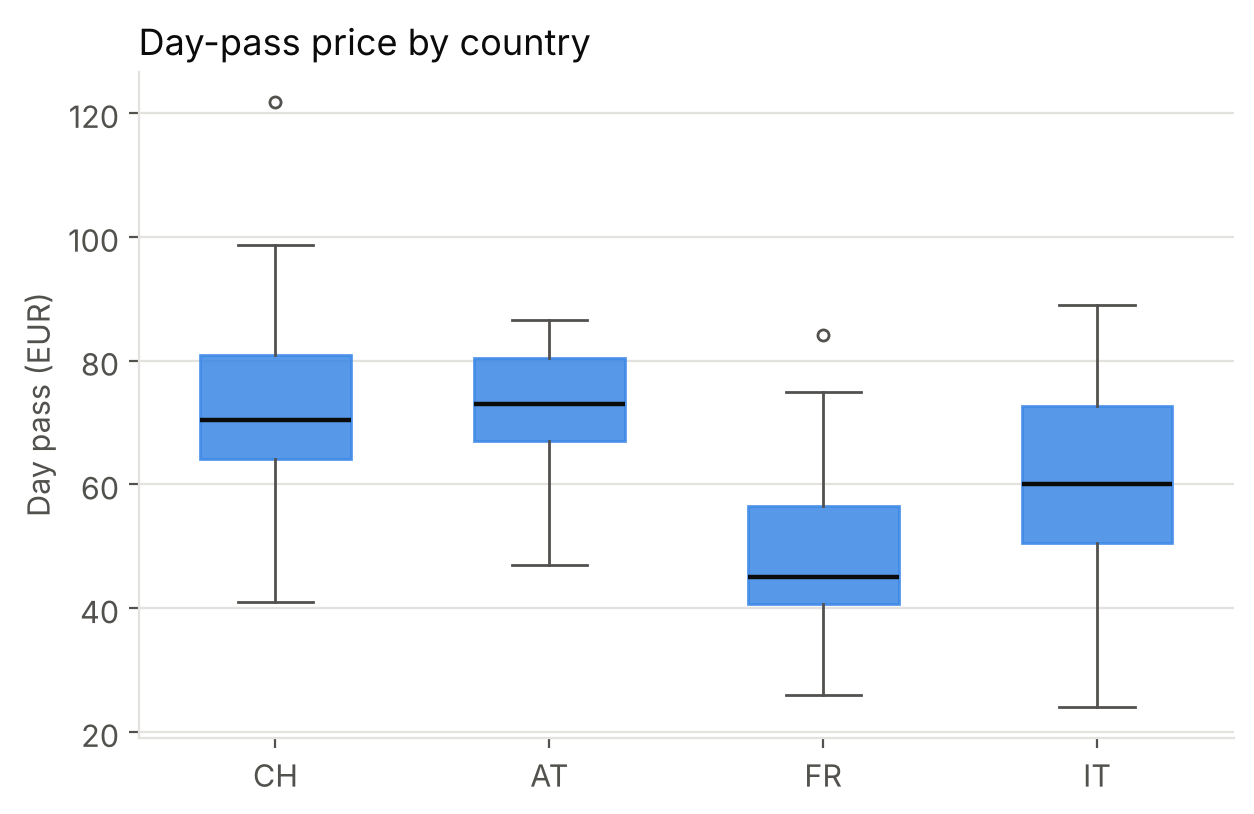

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
bp = ax.boxplot([groups[c] for c in order], tick_labels=order, patch_artist=True, widths=0.55,
                medianprops=dict(color=INK, linewidth=1.6), whiskerprops=dict(color=INK_SOFT), capprops=dict(color=INK_SOFT),
                flierprops=dict(marker="o", markersize=4, markerfacecolor="none", markeredgecolor=INK_SOFT))
for box in bp["boxes"]:
    box.set(facecolor=BLUE_MID, edgecolor=BLUE_MID, alpha=0.85)
ax.set_ylabel("Day pass (EUR)")
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
ax.set_title("Day-pass price by country", loc="left", fontsize=13, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "price_by_country_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

### Assumptions

One-way ANOVA assumes independent observations, roughly normal residuals and equal variances. Levene's test checks the equal variances. If it rejects, the Welch version of ANOVA (which does not need equal variances) and the rank-based Kruskal–Wallis test are the safer choice.

In [7]:
levene_stat, levene_p = stats.levene(*groups.values())
print(f"Levene test for equal variances: statistic = {levene_stat:.2f}, p = {levene_p:.5f}")

Levene test for equal variances: statistic = 6.27, p = 0.00039


In [8]:
# Classical ANOVA, Welch ANOVA and Kruskal-Wallis on the same data
F, p_classic = stats.f_oneway(*groups.values())
welch = anova_oneway([groups[c] for c in order], use_var="unequal")
H, p_kw = stats.kruskal(*groups.values())

grand = d["price_day_eur"].mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups.values())
ss_total = ((d["price_day_eur"] - grand) ** 2).sum()
eta_sq = ss_between / ss_total          # share of the variance in prices explained by the country

anova_table = pd.DataFrame({
    "test": ["One-way ANOVA", "Welch ANOVA", "Kruskal-Wallis"],
    "statistic": [F, welch.statistic, H],
    "p_value": [p_classic, welch.pvalue, p_kw],
})
print(anova_table.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print(f"\nEffect size eta squared = {eta_sq:.3f}  ({eta_sq*100:.1f} % of the variation in price is between countries)")

          test  statistic   p_value
 One-way ANOVA      52.36  4.67e-27
   Welch ANOVA      60.49 6.367e-26
Kruskal-Wallis         99 2.552e-21

Effect size eta squared = 0.352  (35.2 % of the variation in price is between countries)


### Which countries differ? (Tukey HSD)

The overall test only says that *some* means differ. Tukey's test compares all six pairs and controls the overall error rate. Because the variances are unequal, the result is read together with the Welch test.

In [9]:
tukey = pairwise_tukeyhsd(d["price_day_eur"], d["country"], alpha=0.05)
tukey_table = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
tukey_table

,group1,group2,meandiff,p-adj,lower,upper,reject
0,AT,CH,0.3737,0.9981,-5.1741,5.9215,False
1,AT,FR,-23.0415,0.0000,-28.6287,-17.4542,True
2,AT,IT,-11.3708,0.0000,-16.8995,-5.8420,True
3,CH,FR,-23.4151,0.0000,-29.0395,-17.7908,True
4,CH,IT,-11.7444,0.0000,-17.3107,-6.1782,True
5,FR,IT,11.6707,0.0000,6.0651,17.2763,True


**Reading the ANOVA.** The country explains about 35 % of the variation in day-pass prices (eta squared 0.352). All three tests reject H0 at the 5 % level: one-way ANOVA F = 52.4 (p < 0.001), Welch ANOVA F = 60.5 (p < 0.001) and Kruskal–Wallis H = 99.0 (p < 0.001). Levene's test shows unequal variances (p < 0.001; the standard deviation is about 14–16 EUR in CH, IT and FR but 8.5 EUR in AT), so the classical ANOVA alone is not enough. The Welch and the rank-based test give the same answer.

Tukey's test (column `meandiff` = second group minus first group): Switzerland and Austria do not differ (0.4 EUR, p = 0.998). Italy is about 11 to 12 EUR cheaper than both, and France is about 23 EUR cheaper than Switzerland and Austria and about 12 EUR cheaper than Italy.

**Robustness.** With the 269 Alpine areas only (the French Pyrenees, Massif Central and Jura resorts and the Apennines areas are dropped), the conclusions are the same: F = 36.2, Welch F = 37.8, Kruskal–Wallis H = 70.7 (all p < 0.001); the same pairs differ and Switzerland and Austria still do not differ (0.3 EUR). The gap to France shrinks a little (about 21.4 to 21.7 EUR), because the Pyrenees resorts are cheap.

Limits: this describes our sample of 71 to 75 ski areas per country (the scraping used a quota of about 75 per country), not all ski areas. The test compares raw list prices; it does not control for size, elevation or prestige of a resort (that is the regression for SQ3, notebook 07).

### Robustness: Alpine analysis set only

The same tests on the 269 areas inside the Alps. If the conclusions are the same, the choice to keep or drop the 24 non-Alpine areas does not matter for this question.

In [10]:
d_alp = sql("SELECT country, price_day_eur FROM resorts WHERE in_alpine_analysis_set = 1")
g_alp = {c: g["price_day_eur"].to_numpy() for c, g in d_alp.groupby("country")}
F_alp, p_alp = stats.f_oneway(*g_alp.values())
welch_alp = anova_oneway([g_alp[c] for c in order], use_var="unequal")
H_alp, p_kw_alp = stats.kruskal(*g_alp.values())
tukey_alp = pairwise_tukeyhsd(d_alp["price_day_eur"], d_alp["country"], alpha=0.05)
tukey_alp_table = pd.DataFrame(tukey_alp.summary().data[1:], columns=tukey_alp.summary().data[0])
print("n per country:", d_alp.groupby("country").size().to_dict())
print(f"ANOVA F = {F_alp:.1f} (p = {p_alp:.2g}) | Welch F = {welch_alp.statistic:.1f} (p = {welch_alp.pvalue:.2g}) | Kruskal H = {H_alp:.1f} (p = {p_kw_alp:.2g})")
tukey_alp_table[["group1", "group2", "meandiff", "p-adj", "reject"]]

n per country: {'AT': 74, 'CH': 73, 'FR': 53, 'IT': 69}
ANOVA F = 36.2 (p = 1.2e-19) | Welch F = 37.8 (p = 9.2e-18) | Kruskal H = 70.7 (p = 3.1e-15)


,group1,group2,meandiff,p-adj,reject
0,AT,CH,0.3012,0.9991,False
1,AT,FR,-21.4044,0.0000,True
2,AT,IT,-10.7771,0.0000,True
3,CH,FR,-21.7056,0.0000,True
4,CH,IT,-11.0783,0.0000,True
5,FR,IT,10.6273,0.0001,True


## 3. Correlation analysis

How strongly does the day-pass price go together with other resort features? **Pearson** measures a straight-line relation; **Spearman** uses ranks and is less affected by outliers. Each test has a p-value (H0: no correlation).

**Which features are used.** Only features that are *verified* enter the analysis. `slope_km` is used only when `slope_status = 'reparsed'`, `hotels_4_5_star_10km` only when `hotels_status = 'openstreetmap_overpass'`, and `lifts_count` only when it is filled. At the moment this is not the case (see section 3 of notebook 05), so these three are **excluded and the code says so**. The earlier version of this notebook reported a correlation of r = 0.31 between price and 4–5 star hotels; that value was an artefact, because the old hotel column was calculated from slope length and price and not counted.

In [11]:
features = {
    "rating_stars": "Rating (stars)",
    "elevation_top_m": "Top elevation (m)",
    "elevation_base_m": "Base elevation (m)",
    "dist_zurich_km": "Distance to Zurich (km)",
    "dist_nearest_city_km": "Distance to nearest feeder city (km)",
}

# Features with a status flag are used only once they are verified
status_now = sql("SELECT SUM(slope_status <> 'reparsed') AS slope_open, SUM(hotels_status <> 'openstreetmap_overpass') AS hotels_open, "
                 "SUM(lifts_count IS NULL) AS lifts_missing FROM resorts").iloc[0]
excluded = []
if status_now["slope_open"] == 0:
    features["slope_km"] = "Slope length (km)"
else:
    excluded.append("slope_km (not verified: run src/reparse_skiresort.py)")
if status_now["hotels_open"] == 0:
    features["hotels_4_5_star_10km"] = "4-5 star hotels within 10 km"
else:
    excluded.append("hotels_4_5_star_10km (not measured: run src/fetch_hotels_overpass.py)")
if status_now["lifts_missing"] <= 20:
    features["lifts_count"] = "Number of lifts"
else:
    excluded.append("lifts_count (empty: run src/reparse_skiresort.py)")
print("Excluded from the correlation analysis:", excluded if excluded else "nothing")

data = sql("SELECT price_day_eur, " + ", ".join(features) + " FROM resorts WHERE price_day_eur IS NOT NULL")

rows = []
for col, label in features.items():
    x = data[["price_day_eur", col]].dropna()
    r_p, p_p = stats.pearsonr(x["price_day_eur"], x[col])
    r_s, p_s = stats.spearmanr(x["price_day_eur"], x[col])
    rows.append({"feature": label, "n": len(x), "pearson_r": r_p, "pearson_p": p_p, "spearman_rho": r_s, "spearman_p": p_s})
corr = pd.DataFrame(rows).sort_values("pearson_r", ascending=False, key=abs).reset_index(drop=True)
corr_view = corr.assign(pearson_r=corr["pearson_r"].round(2), spearman_rho=corr["spearman_rho"].round(2),
                        pearson_p=corr["pearson_p"].map("{:.2g}".format), spearman_p=corr["spearman_p"].map("{:.2g}".format))
corr_view

Excluded from the correlation analysis: ['slope_km (not verified: run src/reparse_skiresort.py)', 'hotels_4_5_star_10km (not measured: run src/fetch_hotels_overpass.py)', 'lifts_count (empty: run src/reparse_skiresort.py)']


,feature,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,Rating (stars),293,0.64,1.4e-34,0.65,1.7e-36
1,Distance to Zurich (km),293,-0.37,6.4e-11,-0.29,5.3e-07
2,Top elevation (m),293,0.27,3.5e-06,0.20,0.00064
3,Base elevation (m),293,-0.22,0.0002,-0.27,3e-06
4,Distance to nearest feeder city (km),293,-0.18,0.0016,0.06,0.32


**Reading the correlations.** All values are associations, not causes. Only verified columns are used: slope length, number of lifts and 4–5 star hotels are excluded until the re-parsing and the OpenStreetMap count are done (see the message printed above).

The rating of the resort has the strongest relation with the price (Pearson r = 0.64, p < 0.001; Spearman 0.65). Next comes the distance to Zurich: the farther from Zurich, the lower the price (r = −0.37, rho = −0.29, both p < 0.001). This probably reflects the country groups found in the ANOVA (Swiss and Austrian resorts are close to Zurich and dear, French resorts are far and cheaper) more than an effect of the distance itself. A higher top elevation goes with a higher price (r = 0.27, rho = 0.20, p < 0.001), a higher base elevation with a lower price (r = −0.22, rho = −0.27, p < 0.001); our data do not explain the second sign. The distance to the nearest feeder city is weak and not robust: Pearson r = −0.18 (p = 0.002), but Spearman rho = 0.06 (p = 0.32).

**Change from the earlier version of this notebook.** It reported r = 0.31 for 4–5 star hotels (an artefact: the old hotel column was calculated from slope length and price, not counted) and r = −0.08 for the distance to Zurich. The second value was wrong because about 30 resorts had a position that was tens or hundreds of kilometres off in the old table (for example Les 3 Vallées was placed near Mayotte, Nara–Leontica in Zurich and St. Anton am Arlberg in Lower Austria). With the repaired coordinates (notebook 02.4) the distance to Zurich has a clear negative relation with the price. About 20 positions were corrected by hand and are approximate; the independent check of all 293 positions is still to be run (`python src/verify_resort_coordinates.py`).

The rating is an editorial score of the website and partly reflects the quality that a high price pays for, so it should be used with care in a price model.

## 4. Checks

The results are recomputed in a second way, and the diagonal of the matrix is compared with the hours per country of notebook 05.

In [12]:
# 1) F statistic recomputed by hand from the sums of squares
k, n = len(groups), len(d)
ss_within = sum(((g - g.mean()) ** 2).sum() for g in groups.values())
F_hand = (ss_between / (k - 1)) / (ss_within / (n - k))
assert np.isclose(F, F_hand), "ANOVA F differs from the hand calculation"

# 2) eta squared from the F statistic: eta2 = F*(k-1) / (F*(k-1) + (n-k))
assert np.isclose(eta_sq, F * (k - 1) / (F * (k - 1) + (n - k)))

# 3) Matrix: 4 x 4, no empty cells, diagonal equal to the hours per country of notebook 05 (section 4.3)
assert matrix.shape == (4, 4) and not matrix.isna().any().any()
diag = pd.Series(np.diag(matrix.values), index=order).round(2)
nb05_hours = sql('''
    SELECT r.country, ROUND(AVG(r.price_day_eur / e.net_earnings_hour_eur), 2) AS h
    FROM resorts r JOIN v_latest_earnings e ON e.country = r.country
    WHERE r.price_day_eur IS NOT NULL GROUP BY r.country''').set_index("country")["h"].to_dict()
assert diag.to_dict() == nb05_hours, (diag.to_dict(), nb05_hours)
assert (matrix - matrix_median).abs().max().max() < 0.5 and (matrix - matrix_alpine).abs().max().max() < 0.5

# 3b) Same conclusion with the Alpine analysis set only
assert p_alp < 0.001 and welch_alp.pvalue < 0.001 and p_kw_alp < 0.001
assert set(tukey_alp_table.loc[tukey_alp_table["reject"], ["group1", "group2"]].apply(tuple, axis=1)) ==        set(tukey_table.loc[tukey_table["reject"], ["group1", "group2"]].apply(tuple, axis=1))

# 4) Correlation: scipy and pandas agree, and the p-values are between 0 and 1
r_check = data["price_day_eur"].corr(data["rating_stars"])
assert np.isclose(r_check, corr.set_index("feature").loc["Rating (stars)", "pearson_r"], atol=0.006)
assert ((corr["pearson_p"] >= 0) & (corr["pearson_p"] <= 1)).all()

# 5) Tukey: six pairs
assert len(tukey_table) == 6

print("All checks passed.")
con.close()

All checks passed.


## 5. What is still missing

- **Correlations with slope length, lifts and 4–5 star hotels:** these three columns are excluded above until they are verified. Run `python src/reparse_skiresort.py` and `python src/fetch_hotels_overpass.py` in the Codespace, re-run notebook `02.4`, then `05` and this notebook; the code includes the features automatically.
- **ANOVA of snow loss** by country and elevation band: needs the snow table for all resorts. With the 20 Swiss measured stations only one country and two elevation bands exist, which is too little.
- **SQ5 chi-squared test:** see notebook `08_closures_chi_squared.ipynb`; it needs a validated snow-risk class.

The snow indicator is waiting for the group decision (observed station data of Matiu et al. 2021 or CERRA-Land).